In [1]:
import cvxpy as cp
import numpy as np
import matplotlib.pyplot as plt

#DONNEES SYNTHETIQUES - Profil 24h
T = 24
np.random.seed(0)
P_pv = np.maximum(0, 5 * np.sin(np.linspace(0, np.pi, T)) + np.random.normal(0,0.2,T)) # kW
P_load = 2 + 1.5*np.sin(np.linspace(0, 2*np.pi, T) + 1) + np.random.normal(0,0.2,T) # kW
price_grid = np.array([0.1]*7 + [0.3]*10 + [0.1]*7) # $/kWh cher le jour

In [2]:
P_pv

array([0.35281047, 0.76086469, 1.54473145, 2.44018409, 2.97143135,
       2.95998415, 3.8441975 , 4.05457802, 4.41878232, 4.79342431,
       4.92422915, 5.27919855, 5.14055139, 4.91975544, 4.80007726,
       4.50616096, 4.38366528, 3.61314817, 3.21805326, 2.4271006 ,
       1.48140749, 1.47970757, 0.85372049, 0.        ])

In [3]:
P_load

array([3.7161574 , 3.14318503, 3.50870402, 3.41639476, 3.60684256,
       3.34417734, 2.75341757, 2.41660391, 1.75666929, 1.1362003 ,
       1.09559307, 0.89117631, 0.88525119, 0.75988038, 0.43195941,
       0.54953374, 0.60394357, 0.82129629, 1.12204737, 2.2512625 ,
       2.16728403, 2.56974024, 2.74618364, 3.41770455])

In [4]:
price_grid

array([0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3,
       0.3, 0.3, 0.3, 0.3, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1])

Statut : optimal
Valeur objectif : 0.6523159467121622
Coût optimal: $0.65 vs sans batterie: $1.68
Économie: 61.2%
[5.         4.05124555 3.16051581 2.22041499 1.65353423 1.25535031
 1.         1.48890893 2.11057894 2.88102397 3.56987379 4.02239652
 4.43590414 4.74286583 5.04323108 5.49977959 5.9355089  6.48048474
 7.03232769 7.6406721  7.02589483 5.74342265 4.08789586 1.71564676]


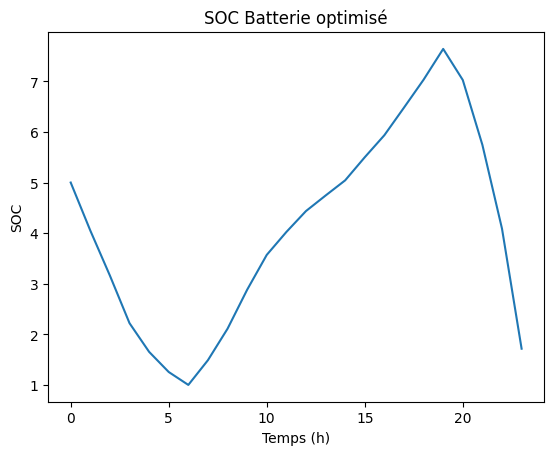

In [11]:


#PARAMETRES BATTERIE
E_bat_max = 10 # kWh
P_bat_max = 3 # kW
eff = 0.9

#VARIABLES CVXPY
P_bat_ch = cp.Variable(T)
P_bat_dis = cp.Variable(T)
P_grid = cp.Variable(T)
P_pv_curtail = cp.Variable(T, nonneg=True)
SOC = cp.Variable(T+1)

#FORMULATION MATHEMATIQUE
constraints = []
SOC0 = 0.5 * E_bat_max
constraints += [SOC[0] == SOC0]
for t in range(T):
    # Bilan puissance: PV + Grid + Dis = Load + Ch
    constraints += [
    P_pv[t] - P_pv_curtail[t]
    + P_grid[t] + P_bat_dis[t]
    == P_load[t] + P_bat_ch[t],

    P_pv_curtail[t] <= P_pv[t]
]
    # SOC dynamique
    constraints += [SOC[t+1] == SOC[t] + eff*P_bat_ch[t] - P_bat_dis[t]/eff]
    # Limites physiques
    constraints += [SOC[t] >= 0.1*E_bat_max, SOC[t] <= 0.9*E_bat_max]
    constraints += [P_bat_ch[t] >=0, P_bat_ch[t] <= P_bat_max]
    constraints += [P_bat_dis[t] >=0, P_bat_dis[t] <= P_bat_max]
    constraints += [P_grid[t] >=0]

#OBJECTIF: Minimiser coût réseau (ROI)
objective = cp.Minimize(cp.sum(cp.multiply(price_grid, P_grid)))

#RESOLUTION
prob = cp.Problem(objective, constraints)
prob.solve()
print("Statut :", prob.status)
print("Valeur objectif :", prob.value)

print(f"Coût optimal: ${prob.value:.2f} vs sans batterie: ${np.sum(price_grid * np.maximum(0, P_load-P_pv)):.2f}")
print(f"Économie: {100*(1-prob.value/np.sum(price_grid * np.maximum(0, P_load-P_pv))):.1f}%")

# Plot SOC
plt.plot(SOC.value[:-1]);
print(SOC.value[:-1])
plt.xlabel("Temps (h)")
plt.ylabel("SOC")
plt.title("SOC Batterie optimisé");
plt.show()